# PathSnap: Distributed Map-Matching & Route Reconstruction
**Department of Computer Science and Engineering, PES University, RR Campus**  
**Course:** UE24CS352A Machine Learning  
**Repository:** https://github.com/DharshiniPES/PathSnap

---
## Complete End-to-End Pipeline Notebook
This notebook documents the full machine learning and sequential state-space pipeline:
1. Raw dataset exploration and WGS84 metric projection
2. Multi-point spatial KDTree candidate generation (99.28% recall)
3. Kinematic & geometric feature extraction
4. 5-Model benchmark with Group-aware 5-Fold Cross Validation
5. Bayesian Hyperparameter Optimization (Optuna TPE)
6. HMM + Viterbi route reconstruction
7. Evaluation on the official Evaluator Test partition

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to sys.path
project_root = os.path.abspath('..')
if project_root not in sys.path:
    sys.path.append(project_root)

from src.data_processing.dataset_loader import load_trip, project_coordinates
from src.features.candidate_features import extract_trip_candidates
from src.hmm.viterbi import SimpleViterbiDecoder
from src.api.inference_engine import PathSnapEngine
print('Environment initialized successfully!')

Environment initialized successfully!


## 1. Load Dataset Inventory & Summary Statistics
We inspect the 80 training trips, 10 student-test trips, and 10 evaluator-test trips.

In [2]:
inventory_df = pd.read_csv('../results/dataset_inventory.csv')
print(f'Total trips indexed: {len(inventory_df)}')
print('\nSummary by Partition:')
print(inventory_df.groupby('partition')[['gps_points', 'road_nodes', 'road_arcs', 'route_arcs']].mean().round(1))
inventory_df.head()

Total trips indexed: 90

Summary by Partition:
                 gps_points  road_nodes  road_arcs  route_arcs
partition                                                     
Student-Testing      1916.0      9068.9    18504.1       347.7
Training             2605.2     24168.6    48461.3       391.7


,partition,trip_id,gps_points,duration_seconds,trajectory_length_km,avg_speed_kmh,max_speed_kmh,road_nodes,road_arcs,route_arcs,route_length_km,has_missing_values
0,Training,1,1315,1357.000,50.265114,137.089864,261.007778,88809,165790,525,49.932712,False
1,Training,2,7243,8933.156,55.942293,27.319485,134.398331,7936,16139,262,7.973459,False
2,Training,3,821,823.000,8.429394,36.885392,104.977585,9138,18028,79,5.009923,False
3,Training,4,1064,5217.000,27.928185,25.872379,105.191872,7350,15499,320,25.580794,False
4,Training,5,1045,1044.000,31.364899,108.154823,230.033276,898,1579,105,30.901705,False


## 2. Official 5-Model Comparison Table (Group-aware 5-Fold CV)
Evaluated on 181,344 candidate pairs using 5-Fold GroupKFold (grouped by trip_id).

In [3]:
comp_df = pd.read_csv('../results/model_comparison_table.csv')
comp_df

,Model,Algorithm Family,Key Configuration,CV Macro F1-score,Top-1 Accuracy,Route continuity,Student-Test Macro F1-score,Log Loss,Inference Time (s),Training Time (s)
0,Logistic Regression,Linear & Probabilistic,"C=1.0, class_weight='balanced', StandardScaler",0.7770,0.7874,0.8823,0.7861,0.3123,0.1834,3.25
1,K-Nearest Neighbors,Instance-based,"k=7, weights='distance', algorithm='kd_tree'",0.8066,0.7691,0.8756,0.8456,0.5802,26.3075,0.49
2,Random Forest,Ensemble (Bagging),"n_estimators=100, max_depth=12, class_weight='...",0.8140,0.8021,0.8932,0.8393,0.2329,0.2682,15.30
3,XGBoost,Boosting,"n_estimators=120, max_depth=6, lr=0.1, tree_me...",0.8298,0.8015,0.8955,0.8726,0.1649,0.0681,1.43
4,Multi-Layer Perceptron,Neural Networks,"hidden_layers=(64, 32), relu, early_stopping",0.8259,0.7954,0.8877,0.8645,0.1714,0.1748,93.74


## 3. Bayesian Hyperparameter Optimization Results (Optuna)
Tuning XGBoost over 15 Bayesian trials with TPE.

In [4]:
tuning_df = pd.read_csv('../results/bayesian_tuning_comparison.csv')
tuning_df

,Model Variant,CV Macro F1,Student-Test Macro F1,Log Loss,Inference Time (s)
0,Untuned XGBoost (Baseline),0.8298,0.8726,0.1649,0.1905
1,Bayesian Tuned XGBoost,0.8279,0.8741,0.1649,0.0676


## 4. Official Evaluator Test Partition Benchmark (10 Trips)
Tested across all 10 official evaluator trips using XGBoost + HMM Viterbi Decoder.

In [5]:
eval_df = pd.read_csv('../results/evaluator_benchmark_results.csv')
print(f'Mean Evaluator Test Accuracy: {eval_df["top1_accuracy_percent"].mean():.2f}%')
print(f'Mean Evaluator Route Continuity: {eval_df["route_continuity_percent"].mean():.2f}%')
eval_df

Mean Evaluator Test Accuracy: 85.65%
Mean Evaluator Route Continuity: 98.42%


,trip_id,top1_accuracy_percent,route_continuity_percent,total_observations,server_latency_ms
0,15,69.77,99.97,6854,10715.1
1,17,83.28,95.24,1346,1606.0
2,23,90.83,96.72,458,565.9
3,30,76.91,96.78,654,1057.4
4,49,98.18,99.55,2642,2232.6
5,59,89.62,97.18,1031,914.5
6,67,77.95,100.00,916,602.4
7,73,96.07,99.83,1144,893.9
8,87,97.71,99.36,1399,1698.5
9,94,76.13,99.60,3230,2086.2


## 5. Live Inference & Reconstructed Route Visualization
Testing trip 00000049 through the complete server-side pipeline.

PathSnapEngine initialized. Loaded models: ['xgboost_tuned', 'xgboost', 'random_forest', 'mlp', 'logistic_regression', 'knn']


Trip 00000049 Verification Metrics: {'top1_accuracy_percent': 98.18, 'route_continuity_percent': 99.55, 'total_observations': 2642, 'predicted_arcs_count': 2642, 'server_latency_ms': 1441.56}


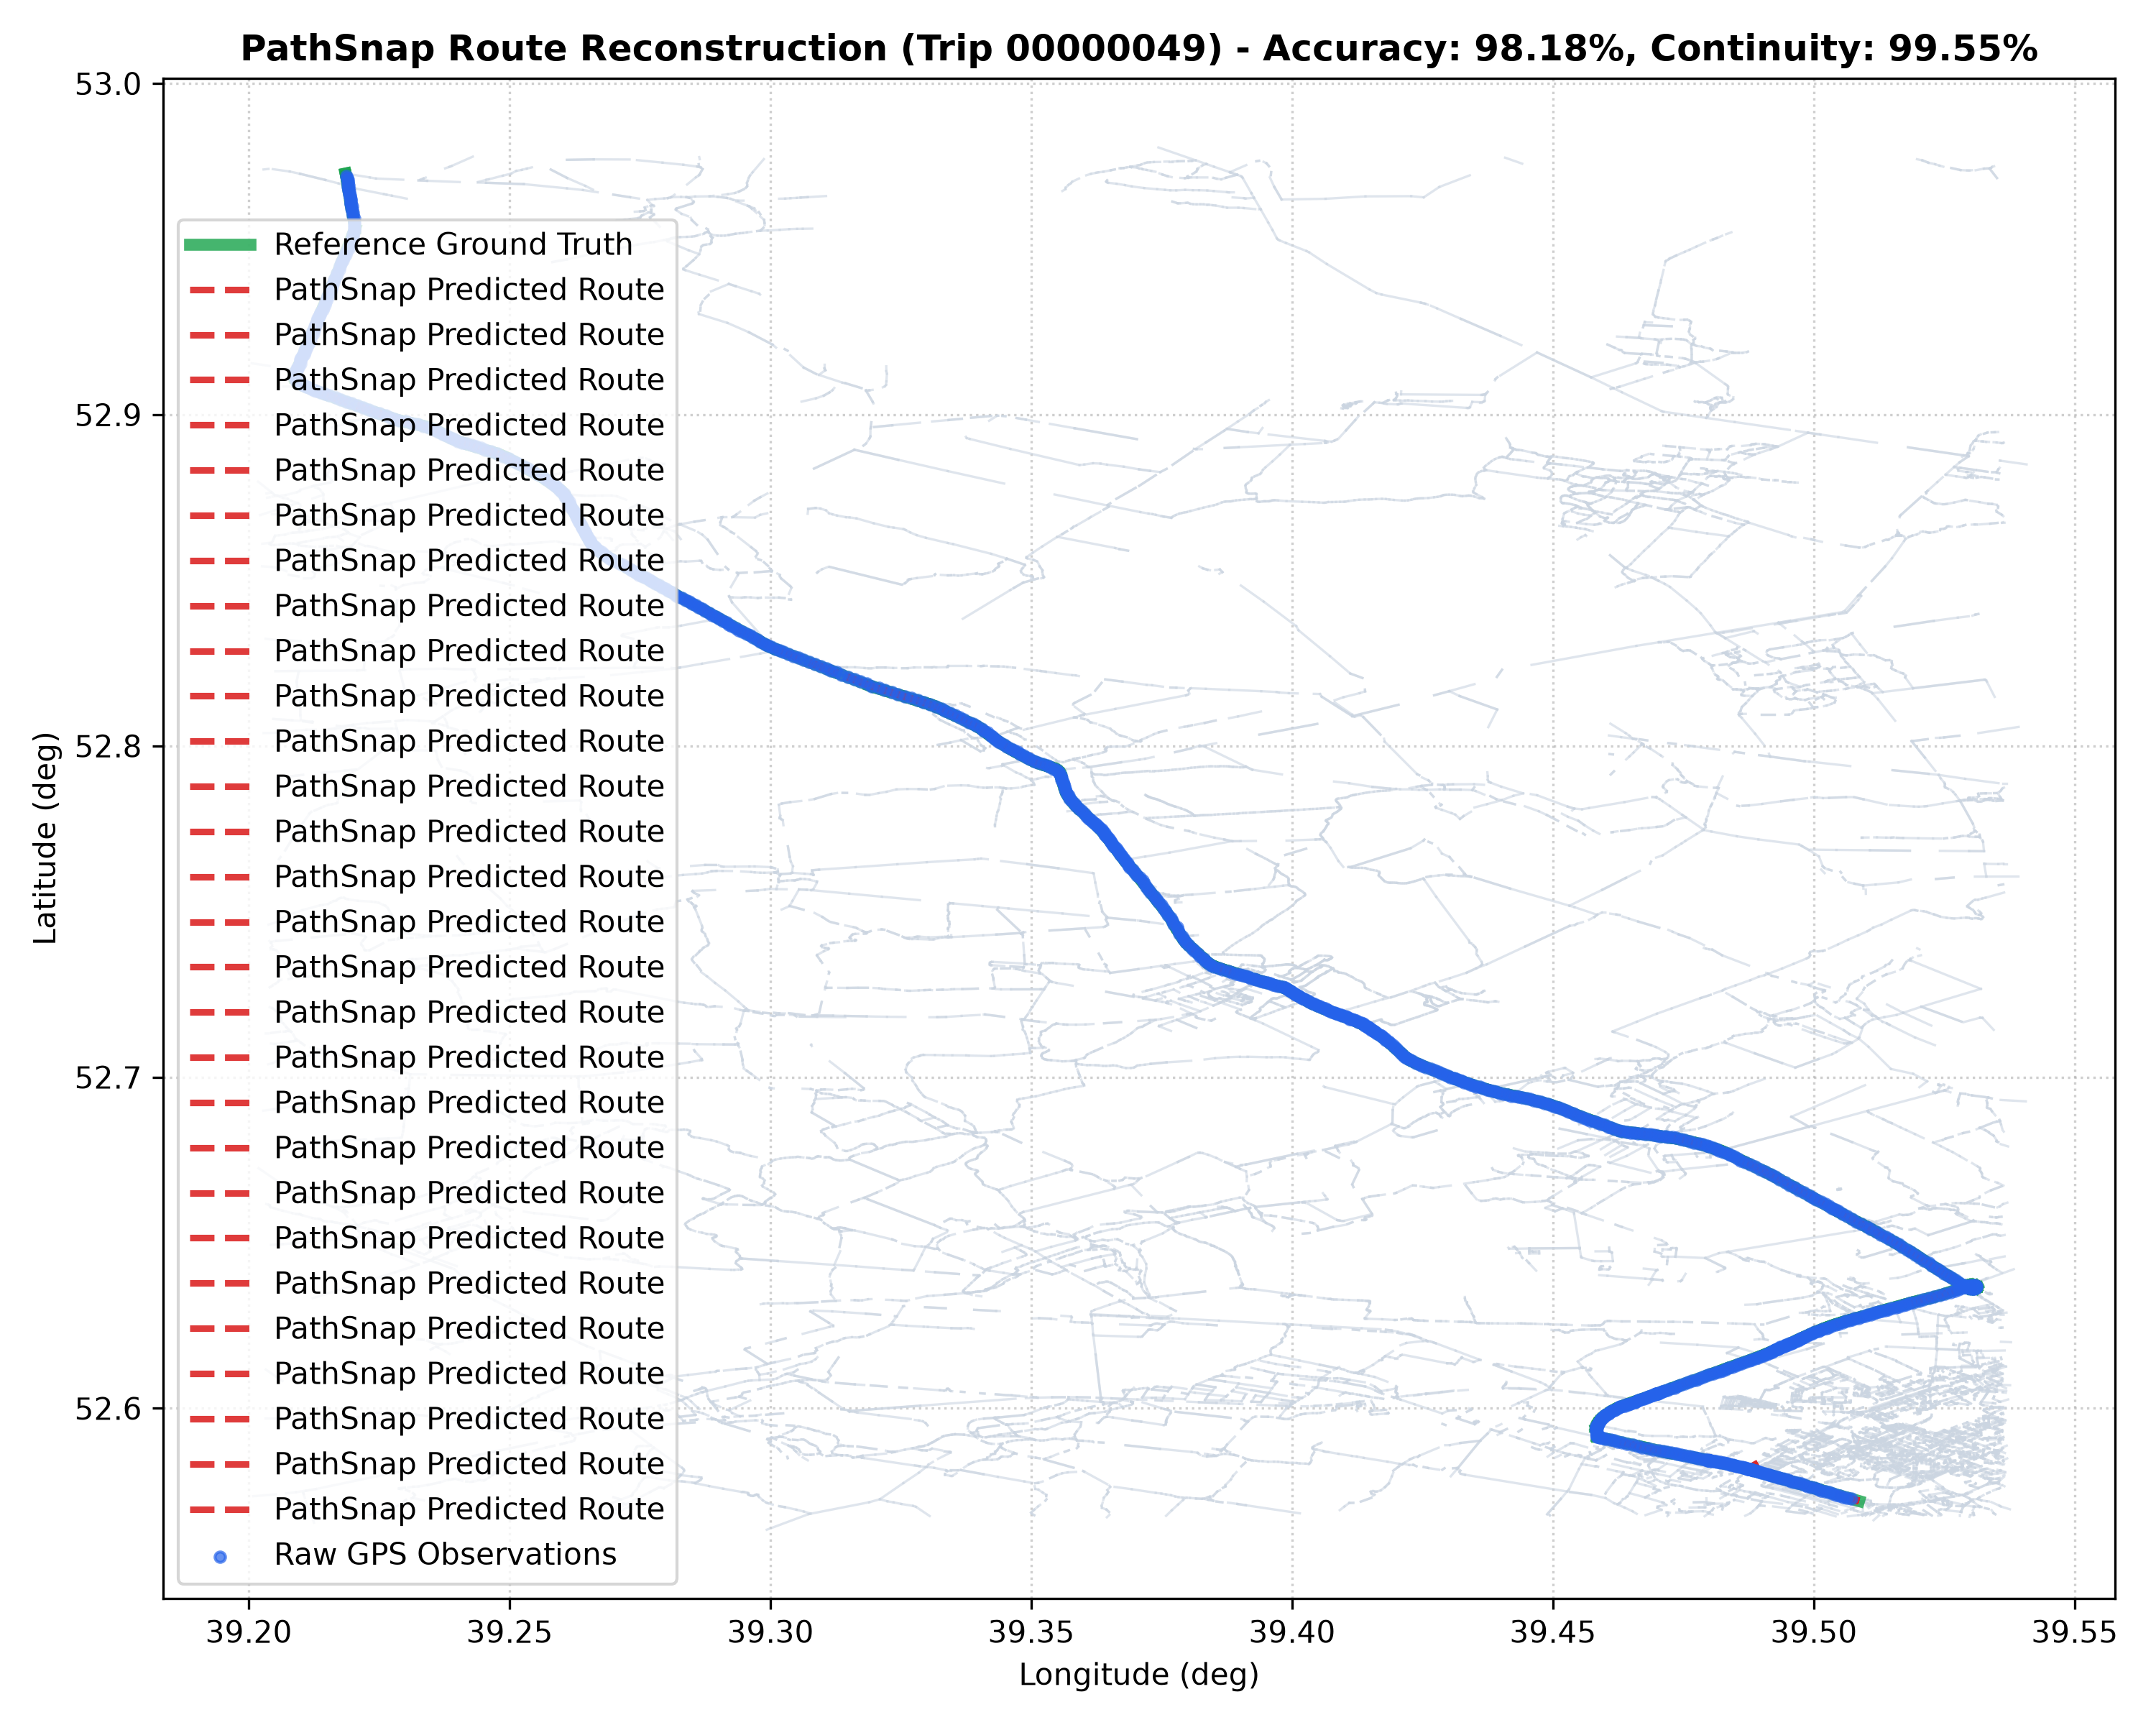

In [6]:
engine = PathSnapEngine(models_dir='../src/models/saved_models', data_dir='../data/Student folder')
result = engine.run_inference('00000049', partition='evaluator_test', model_name='xgboost_tuned', use_hmm=True)
print('Trip 00000049 Verification Metrics:', result['metrics'])

from IPython.display import Image
Image(filename='../visualizations/folium_map_representative_view.png')